In [1]:
# Merge - Farah vs Zaineb: a FAIR comparison of the two works, model by model
#
# Zaineb trained the same 4 models (SVM, decision tree, CNN, ResNet50) in her own repo, but with other data
# (3784 wavs: no cleaning, 858 abnormal), other features and other folds (split by patient).
# Her numbers can't be compared with mine directly. So here, I run HER methods on MY protocol:
#   - the same data: my 3681 clean wavs (the same cleaning rules as all my notebooks), read in the same order
#   - the same 3 folds: KFold(n_splits=3, shuffle=True, random_state=1), like notebooks 02, 03, 04, 06
#   - the same metrics: accuracy, precision, recall, f1 of the abnormal class (the sick hearts)
# My numbers come from MLflow (experiment audio_benchmark, the runs of notebooks 02, 03, 04, 06).
#
# Decision rule for each model (in this order): 1. it matches the project PDF, 2. it runs on my PC,
# 3. the highest mean validation RECALL of abnormal (then F1), 4. simple enough to explain.
# The decisions are written in MERGE_NOTES.md (repo root).

In [2]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"    # hide the TensorFlow info messages

import pickle
from glob import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import IPython.display as ipd

from sklearn.model_selection import KFold, GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPooling2D, Dropout
from keras.layers import GlobalAveragePooling2D, Dense
from keras.utils import to_categorical
from keras.applications.resnet50 import ResNet50

import mlflow

tf.get_logger().setLevel("ERROR")

In [3]:
# my folders (the same as in the other notebooks)
project_folder = "D:/MLOps_Project/"
ourdataset_folder = "D:/MLOps_Project/ourdataset/train/"


def load_data(file_name):
    with open(file_name, "rb") as f:
        return pickle.load(f)


def save_data(data, file_name):
    with open(file_name, "wb") as f:
        pickle.dump(data, f)


SR = 2000    # every wav at 2000 Hz, like all my notebooks

In [4]:
# ==================== 1. My clean wavs + Zaineb's features (72 numbers per wav) ====================
# Zaineb's features (her notebooks 02 and 03), computed on the WHOLE wav (no 5 s cut):
#   duration, SNR, mean and std of 20 Mel bands, mean and std of 13 MFCC, spectral centroid, zero-crossing rate
# Her settings: n_fft = 512, hop_length = 128, 20 Mel bands, 2000 Hz.
def signaltonoise(a, axis=0, ddof=0):
    a = np.asanyarray(a)
    m = a.mean(axis)
    sd = a.std(axis=axis, ddof=ddof)
    return np.where(sd == 0, 0, m / sd)


def zaineb_features(signal):
    duration = len(signal) / SR
    snr = float(signaltonoise(signal / max(np.max(np.abs(signal)), 1e-10)))
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=20)
    S_DB = librosa.power_to_db(S, ref=np.max)
    mfcc = librosa.feature.mfcc(y=signal, sr=SR, n_mfcc=13, n_fft=512, hop_length=128, n_mels=20)
    centroid = librosa.feature.spectral_centroid(y=signal, sr=SR, n_fft=512, hop_length=128)
    zcr = librosa.feature.zero_crossing_rate(signal, frame_length=512, hop_length=128)
    return np.concatenate([[duration, snr], np.mean(S_DB, axis=1), np.std(S_DB, axis=1),
                           np.mean(mfcc, axis=1), np.std(mfcc, axis=1),
                           [np.mean(centroid), np.std(centroid), np.mean(zcr), np.std(zcr)]])


def zaineb_spectrogram(signal):
    # her CNN input: the middle 5 s (a shorter wav is repeated), 64 Mel bands, n_fft 512, hop 128 -> 64 x 79
    n = SR * 5
    if len(signal) < n:
        signal = np.tile(signal, int(np.ceil(n / len(signal))))[:n]
    else:
        start = (len(signal) - n) // 2
        signal = signal[start:start + n]
    S = librosa.feature.melspectrogram(y=signal, sr=SR, n_fft=512, hop_length=128, n_mels=64)
    return librosa.power_to_db(S, ref=np.max).astype("float32")


cache_file = project_folder + "merge_zaineb_features.data"
if os.path.exists(cache_file):
    files, y, X72, specs = load_data(cache_file)
else:
    files, labels, features, spectrograms = [], [], [], []
    for class_name in ["abnormal", "normal"]:                     # abnormal first, like all my notebooks
        for file in glob(ourdataset_folder + class_name + "/*.wav"):
            signal, rate = librosa.load(file, sr=SR)
            # my cleaning rules (the same in every notebook): too short, silent, saturated -> skipped
            too_short = len(signal) < 2 * SR
            silent = np.max(np.abs(signal)) < 0.001
            saturated = np.mean(np.abs(signal) >= 0.99) > 0.01
            if too_short or silent or saturated:
                continue
            files.append(os.path.basename(file))
            labels.append(1 if class_name == "abnormal" else 0)
            features.append(zaineb_features(signal))
            spectrograms.append(zaineb_spectrogram(signal))
    y = np.array(labels)
    X72 = np.array(features)
    specs = np.array(spectrograms)
    save_data((files, y, X72, specs), cache_file)

print(len(files), "clean wavs | normal:", np.sum(y == 0), "| abnormal:", np.sum(y == 1))
print("Zaineb's features:", X72.shape, "| Zaineb's spectrograms:", specs.shape)

# the same wavs in the same order as my caches? (my labels are saved by notebook 03)
my_labels = np.array(load_data(project_folder + "mfcc_features_tree_b.data"))
assert len(my_labels) == len(y) and np.all(my_labels == y), "not the same wavs / order as my notebooks!"
print("Same wavs and same order as my notebooks: OK")

3681 clean wavs | normal: 2855 | abnormal: 826
Zaineb's features: (3681, 72) | Zaineb's spectrograms: (3681, 64, 79)
Same wavs and same order as my notebooks: OK


In [5]:
# ==================== 2. My 3 folds + the metrics ====================
kfold = KFold(n_splits=3, shuffle=True, random_state=1)    # the SAME 3 folds as my notebooks 02, 03, 04, 06
folds = list(kfold.split(X72))


def metrics_of(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred),     # precision, recall, f1: of the abnormal class
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred)}


comparison = []    # 1 line per (model, method): the mean of the 3 folds


def add_result(model, method, fold_rows):
    table = pd.DataFrame(fold_rows)
    line = {"model": model, "method": method}
    for metric in ["accuracy", "precision", "recall", "f1"]:
        line[metric] = table[metric].mean()
    comparison.append(line)
    print(model, "-", method, ": recall = {:.3f} | f1 = {:.3f} | precision = {:.3f} | accuracy = {:.3f}".format(
        line["recall"], line["f1"], line["precision"], line["accuracy"]))

In [6]:
# ==================== 3. SVM: Zaineb's features (22 basic / 72 extended) and her GridSearch ====================
# basic = duration, SNR, mean of the 20 Mel bands (22) | extended = all 72
feature_sets = {"basic (22)": np.arange(22), "extended (72)": np.arange(72)}

for set_name in feature_sets:
    columns = feature_sets[set_name]
    rows = []
    for train_index, test_index in folds:
        model = make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced"))
        model.fit(X72[train_index][:, columns], y[train_index])
        rows.append(metrics_of(y[test_index], model.predict(X72[test_index][:, columns])))
    add_result("SVM", "Zaineb - rbf, " + set_name, rows)

# her tuned version: C and gamma chosen by GridSearchCV INSIDE the train part of each fold (inner 3 folds, F1)
rows = []
for train_index, test_index in folds:
    grid = {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 0.01, 0.1]}
    search = GridSearchCV(make_pipeline(StandardScaler(), SVC(kernel="rbf", class_weight="balanced")), grid,
                          cv=KFold(n_splits=3, shuffle=True, random_state=1), scoring="f1", n_jobs=-1)
    search.fit(X72[train_index], y[train_index])
    rows.append(metrics_of(y[test_index], search.predict(X72[test_index])))
add_result("SVM", "Zaineb - rbf, extended (72), tuned C/gamma", rows)

SVM - Zaineb - rbf, basic (22) : recall = 0.883 | f1 = 0.653 | precision = 0.518 | accuracy = 0.789


SVM - Zaineb - rbf, extended (72) : recall = 0.887 | f1 = 0.702 | precision = 0.581 | accuracy = 0.831


SVM - Zaineb - rbf, extended (72), tuned C/gamma : recall = 0.795 | f1 = 0.737 | precision = 0.687 | accuracy = 0.872


In [7]:
# ==================== 4. Decision tree: Zaineb's features + her depth chosen inside each fold ====================
# Her method: for each fold, max_depth (1 to 15) is chosen by a 3-fold cross-validation on the TRAIN part only
# (F1 of abnormal), so the validation third is never used to choose the depth. I do the same with my 26 MFCC.
def choose_depth(X_train, y_train):
    inner = KFold(n_splits=3, shuffle=True, random_state=1)
    best_depth = 1
    best_f1 = -1
    for depth in range(1, 16):
        f1_list = []
        for inner_train, inner_val in inner.split(X_train):
            tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0)
            tree.fit(X_train[inner_train], y_train[inner_train])
            f1_list.append(f1_score(y_train[inner_val], tree.predict(X_train[inner_val])))
        if np.mean(f1_list) > best_f1:
            best_f1 = np.mean(f1_list)
            best_depth = depth
    return best_depth


X26 = np.array(load_data(project_folder + "mfcc_features_tree_a.data"))    # my 26 MFCC features (notebook 03)
for name, X in [("Zaineb - 72 features, depth chosen per fold", X72),
                ("Farah features (26 MFCC), depth chosen per fold", X26)]:
    rows = []
    depths = []
    for train_index, test_index in folds:
        depth = choose_depth(X[train_index], y[train_index])
        tree = DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=0)
        tree.fit(X[train_index], y[train_index])
        rows.append(metrics_of(y[test_index], tree.predict(X[test_index])))
        depths.append(depth)
    add_result("DecisionTree", name + " " + str(depths), rows)

DecisionTree - Zaineb - 72 features, depth chosen per fold [6, 5, 9] : recall = 0.863 | f1 = 0.656 | precision = 0.531 | accuracy = 0.797


DecisionTree - Farah features (26 MFCC), depth chosen per fold [6, 9, 5] : recall = 0.825 | f1 = 0.630 | precision = 0.515 | accuracy = 0.781


In [8]:
# ==================== 5. CNN: Zaineb's network on my folds ====================
# Her CNN: 64 x 79 spectrogram, 3 x (Conv2D + BatchNorm + ReLU + MaxPooling + Dropout 0.2), GlobalAveragePooling,
# Dense 64, softmax (2 classes), Adam. Training stops when the loss of a validation part (25% of the train part,
# never the validation third) stops going down for 12 epochs (EarlyStopping), at most 60 epochs.
def build_zaineb_cnn():
    model = Sequential()
    model.add(Input(shape=(64, 79, 1)))
    for filters in [16, 32, 64]:
        model.add(Conv2D(filters, (3, 3), padding="same"))
        model.add(BatchNormalization(momentum=0.9))
        model.add(Activation("relu"))
        model.add(MaxPooling2D((2, 2)))
        model.add(Dropout(0.2))
    model.add(GlobalAveragePooling2D())
    model.add(Dense(64, activation="relu"))
    model.add(Dropout(0.3))
    model.add(Dense(2, activation="softmax"))
    model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
    return model


def balanced_weights(labels):
    return {0: len(labels) / (2 * np.sum(labels == 0)), 1: len(labels) / (2 * np.sum(labels == 1))}


images = ((specs + 80) / 80).reshape(len(specs), 64, 79, 1)
rows = []
for train_index, test_index in folds:
    fit_index, stop_index = train_test_split(train_index, test_size=0.25, stratify=y[train_index], random_state=42)
    keras.utils.set_random_seed(42)
    model = build_zaineb_cnn()
    model.fit(images[fit_index], to_categorical(y[fit_index], 2), batch_size=32, epochs=60,
              validation_data=(images[stop_index], to_categorical(y[stop_index], 2)),
              class_weight=balanced_weights(y[fit_index]), verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=12, restore_best_weights=True)])
    y_pred = np.argmax(model.predict(images[test_index], verbose=0), axis=1)
    rows.append(metrics_of(y[test_index], y_pred))
add_result("CNN", "Zaineb - BatchNorm + GlobalAveragePooling + softmax, early stopping", rows)

CNN - Zaineb - BatchNorm + GlobalAveragePooling + softmax, early stopping : recall = 0.798 | f1 = 0.705 | precision = 0.632 | accuracy = 0.850


In [9]:
# ==================== 6. ResNet50 transfer learning: Zaineb's version on my folds ====================
# Her version: the grey spectrogram (64 x 79, 0-1) -> x 255 -> copied in 3 channels -> 128 x 128 -> ImageNet mean
# colour removed -> frozen ResNet50 (2048 numbers) -> head Dropout + Dense 256 + Dropout + sigmoid, Adam 0.001,
# early stopping on a validation part of the train part (patience 10, at most 50 epochs).
base_model = ResNet50(weights="imagenet", include_top=False, pooling="avg", input_shape=(128, 128, 3))
base_model.trainable = False

embeddings = []
for start in range(0, len(images), 64):
    batch = np.repeat(images[start:start + 64] * 255, 3, axis=-1)                  # grey -> 3 channels
    batch = tf.image.resize(batch, (128, 128)).numpy()                             # 64 x 79 -> 128 x 128
    batch = batch - np.array([103.939, 116.779, 123.68])                           # ImageNet mean colour
    embeddings.append(base_model.predict(batch, verbose=0))
embeddings = np.concatenate(embeddings)
print("ResNet50 embeddings:", embeddings.shape)


def build_zaineb_head():
    head = Sequential()
    head.add(Input(shape=(2048,)))
    head.add(Dropout(0.3))
    head.add(Dense(256, activation="relu"))
    head.add(Dropout(0.3))
    head.add(Dense(1, activation="sigmoid"))
    head.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    return head


rows = []
for train_index, test_index in folds:
    fit_index, stop_index = train_test_split(train_index, test_size=0.25, stratify=y[train_index], random_state=42)
    keras.utils.set_random_seed(42)
    head = build_zaineb_head()
    head.fit(embeddings[fit_index], y[fit_index], batch_size=32, epochs=50,
             validation_data=(embeddings[stop_index], y[stop_index]),
             class_weight=balanced_weights(y[fit_index]), verbose=0,
             callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)])
    y_pred = (head.predict(embeddings[test_index], verbose=0).ravel() > 0.5).astype(int)
    rows.append(metrics_of(y[test_index], y_pred))
add_result("ResNet50", "Zaineb - grey 128 x 128, head Dense 256, early stopping", rows)

ResNet50 embeddings: (3681, 2048)


ResNet50 - Zaineb - grey 128 x 128, head Dense 256, early stopping : recall = 0.757 | f1 = 0.740 | precision = 0.723 | accuracy = 0.881


In [10]:
# ==================== 7. My results on the same folds (from MLflow, experiment audio_benchmark) ====================
mlflow.set_tracking_uri("http://localhost:5000")
runs = mlflow.search_runs(experiment_names=["audio_benchmark"], order_by=["start_time DESC"])
runs = runs[runs["metrics.mean_recall"].notna()]       # only the main runs (not the fold runs)

my_runs = {"SVM": "svm_rbf_5s", "DecisionTree": "decision_tree_gini_depth10", "CNN": "cnn", "ResNet50": "resnet50"}
my_methods = {"SVM": "Farah - rbf, Mel 30 bands flattened (5 s)", "DecisionTree": "Farah - 26 MFCC, gini, depth 10",
              "CNN": "Farah - Conv 16/32/64 + Flatten + Dense 32 + sigmoid, 20 epochs",
              "ResNet50": "Farah - magma 224 x 224, head BN + Dense 128, 30 epochs"}
for model in my_runs:
    run = runs[runs["tags.mlflow.runName"] == my_runs[model]].iloc[0]    # the latest run with this name
    comparison.append({"model": model, "method": my_methods[model],
                       "accuracy": run["metrics.mean_accuracy"], "precision": run["metrics.mean_precision"],
                       "recall": run["metrics.mean_recall"], "f1": run["metrics.mean_f1"]})

table = pd.DataFrame(comparison).sort_values(["model", "recall"], ascending=[True, False]).reset_index(drop=True)
ipd.display(table.round(3))

,model,method,accuracy,precision,recall,f1
0,CNN,Farah - Conv 16/32/64 + Flatten + Dense 32 + s...,0.778,0.510,0.925,0.655
1,CNN,Zaineb - BatchNorm + GlobalAveragePooling + so...,0.850,0.632,0.798,0.705
2,DecisionTree,"Zaineb - 72 features, depth chosen per fold [6...",0.797,0.531,0.863,0.656
3,DecisionTree,"Farah features (26 MFCC), depth chosen per fol...",0.781,0.515,0.825,0.630
4,DecisionTree,"Farah - 26 MFCC, gini, depth 10",0.810,0.559,0.718,0.629
5,ResNet50,"Farah - magma 224 x 224, head BN + Dense 128, ...",0.889,0.730,0.800,0.763
6,ResNet50,"Zaineb - grey 128 x 128, head Dense 256, early...",0.881,0.723,0.757,0.740
7,SVM,"Zaineb - rbf, extended (72)",0.831,0.581,0.887,0.702
8,SVM,"Zaineb - rbf, basic (22)",0.789,0.518,0.883,0.653
9,SVM,"Farah - rbf, Mel 30 bands flattened (5 s)",0.791,0.521,0.829,0.639


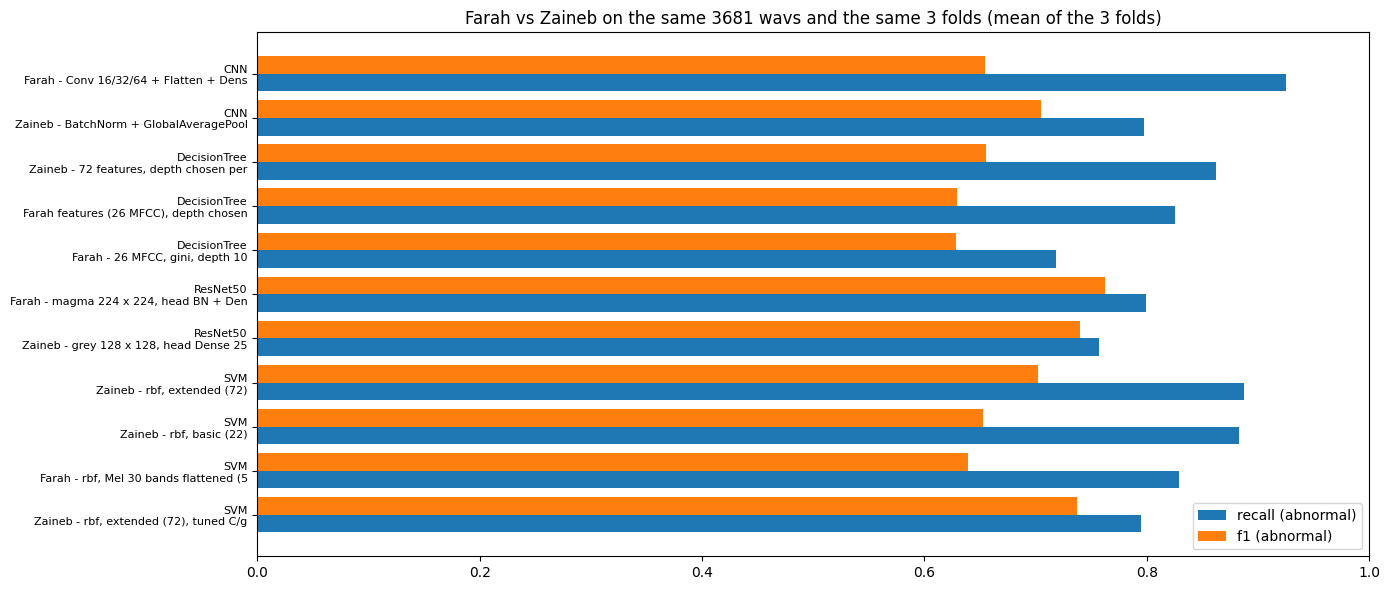

In [11]:
# ONE figure: recall and F1 of abnormal for every method, grouped by model
plt.figure(figsize=(14, 6))
names = [row["model"] + "\n" + row["method"][:38] for _, row in table.iterrows()]
x = np.arange(len(table))
plt.barh(x + 0.2, table["recall"], height=0.4, label="recall (abnormal)")
plt.barh(x - 0.2, table["f1"], height=0.4, label="f1 (abnormal)")
plt.yticks(x, names, fontsize=8)
plt.xlim(0, 1)
plt.gca().invert_yaxis()
plt.title("Farah vs Zaineb on the same 3681 wavs and the same 3 folds (mean of the 3 folds)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(project_folder + "models plots/merge_farah_vs_zaineb.png")
plt.show()